# Évaluation à l'échelle globale

In [1]:
import numpy as np, xarray as xr

OUT = '/SCRATCH/n23nguye/mapping_2023_2025/osse_with_ose_footprint/'

wo   = xr.open_dataset(OUT + 'Glorys12_alongtrack_S7nadirsNswotKarinWithLweRemoved_real_2023-01-01_2025-07-31_wo_Altika.nc').sel(time='2024')['sla']
wi   = xr.open_dataset(OUT + 'Glorys12_alongtrack_S7nadirsNswotKarinWithLweRemoved_real_2023-01-01_2025-07-31_with_Altika.nc').sel(time='2024')['sla']

# AltiKa-only truth = pixels present in `with` but not in `wo`
alt_truth = wi.where(np.isfinite(wi) & np.isnan(wo))          # GLORYS SLA on the AltiKa footprint

In [2]:
import sys, numpy as np, pandas as pd, xarray as xr
import pyinterp.backends.xarray as pbx
sys.path.append('/Odyssey/private/n23nguye/2023a_SSH_mapping_OSE/Notebooks')   # repo containing src/
from src.mod_spectral import compute_psd_scores_v2
from src.mod_plot import plot_effective_resolution_png

YEAR_SHIFT = 5

def sample_grid_on_track(grid_da, times, lat, lon, year_shift=0):
    """Sample a gridded (time,latitude,longitude) field onto 1-D track points."""
    grid_da = grid_da.sortby('latitude').sortby('longitude')
    # ensure pyinterp can identify the axes (needs CF units, not just names)
    grid_da['longitude'].attrs.setdefault('units', 'degrees_east')
    grid_da['latitude'].attrs.setdefault('units',  'degrees_north')
    
    is360 = float(grid_da.longitude.max()) > 180.0 + 1e-6
    gt = pd.DatetimeIndex(grid_da['time'].values)
    gkey = pd.Series(np.arange(gt.size), index=pd.MultiIndex.from_arrays([gt.year, gt.month, gt.day]))
    obs = pd.DatetimeIndex(times)
    gidx = gkey.reindex(list(zip(obs.year - year_shift, obs.month, obs.day))).to_numpy('float64')
    lo = (np.mod(lon,360.0) if is360 else ((lon+180.0)%360.0-180.0)).astype('float64')
    la = np.asarray(lat,'float64'); out = np.full(obs.size, np.nan)
    for gi in np.unique(gidx[~np.isnan(gidx)]).astype(int):
        m = gidx == gi; g2 = pbx.Grid2D(grid_da.isel(time=gi).load())
        try:    out[m] = g2.bivariate(dict(longitude=lo[m], latitude=la[m]), interpolator='bilinear', num_threads=0)
        except TypeError: out[m] = g2.bivariate(dict(longitude=lo[m], latitude=la[m]))
    return out

# 1) real 1-D Saral/AltiKa track geometry for 2024
alt = xr.open_dataset('/Odyssey/private/n23nguye/2023a_SSH_mapping_OSE/Notebooks/alg_2024_miost_mask.nc').sortby('time').sel(time='2024')
t, lat, lon = alt['time'].values, alt['latitude'].values.ravel(), alt['longitude'].values.ravel()

# 2) GLORYS truth (year-shift -5) -> sla_unfiltered   (GLORYS = your earlier `GLORYS` path)
glorys = xr.open_dataset("/SCRATCH/n23nguye/glorys12_2010_2019_daily_sla_4th_target_gridded_alongtrack.nc")['sla']
glorys['longitude'].attrs['units'] = 'degrees_east'
glorys['latitude'].attrs['units']  = 'degrees_north'
print("glorys: ", glorys)
sla_unfiltered = sample_grid_on_track(glorys, t, lat, lon, year_shift=YEAR_SHIFT)


/Odyssey/private/n23nguye/envs/nga/miniconda/envs/dc/lib/python3.10/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


glorys:  <xarray.DataArray 'sla' (time: 3652, latitude: 720, longitude: 1440)> Size: 30GB
[3786393600 values with dtype=float64]
Coordinates:
  * time       (time) datetime64[ns] 29kB 2010-01-01 2010-01-02 ... 2019-12-31
  * latitude   (latitude) float32 3kB -89.88 -89.62 -89.38 ... 89.38 89.62 89.88
  * longitude  (longitude) float64 12kB -179.9 -179.6 -179.4 ... 179.6 179.9


points feeding spectral analysis: 14644826
Averaged effective resolution: 17.1941 km


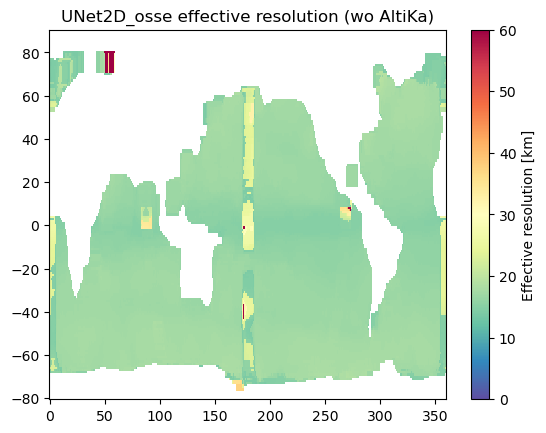

In [3]:
# 3) OSSE reconstruction (2024) -> msla_interpolated
recon = xr.open_dataset('/Odyssey/private/n23nguye/4dvarnet-global-mapping-Daniel-version/inference/outputs/'
                        'Unet-Train6NadirsNSWOT_test7NadirsNSWOTLweRemoved_OSSEinference-n10-std0.2.nc')['sla']
if 'lat' in recon.dims or 'lat' in recon.coords: recon = recon.rename({'lat':'latitude','lon':'longitude'})
msla_interpolated = sample_grid_on_track(recon, t, lat, lon, year_shift=0)

# 4) assemble the 1-D ds_interp the challenge expects (exact names!)
ds_interp = xr.Dataset(
    dict(sla_unfiltered=('time', sla_unfiltered.astype('float64')),
         msla_interpolated=('time', msla_interpolated.astype('float64'))),
    coords=dict(time=('time', t), latitude=('time', lat.astype('float64')), longitude=('time', lon.astype('float64'))),
).sortby('time').dropna('time')
print('points feeding spectral analysis:', ds_interp.time.size)

# 5) effective resolution via the data-challenge routine
import os; os.makedirs('./results', exist_ok=True)
psd_out = './results/psd_Unet-Train6NadirsNSWOT_test7NadirsNSWOTLweRemoved_OSSEinference_wo_altika.nc'
compute_psd_scores_v2(ds_interp, psd_out, method_name='Unet-Train6NadirsNSWOT_test7NadirsNSWOTLweRemoved_OSSEinference-wo-altika')

# 6) global number + safe map (avoids the cartopy colorbar bug you hit before)
import matplotlib.pyplot as plt
psd = xr.open_dataset(psd_out)
print(f"Averaged effective resolution: {float(np.nanmean(psd.effective_resolution)):.4f} km")
m = plt.pcolormesh(psd.lon, psd.lat, psd.effective_resolution, vmin=0, vmax=60, cmap='Spectral_r', shading='auto')
plt.colorbar(m, label='Effective resolution [km]'); plt.title('UNet2D_osse effective resolution (wo AltiKa)'); plt.show()

points feeding spectral analysis: 14644826
Averaged effective resolution: 20.7662 km


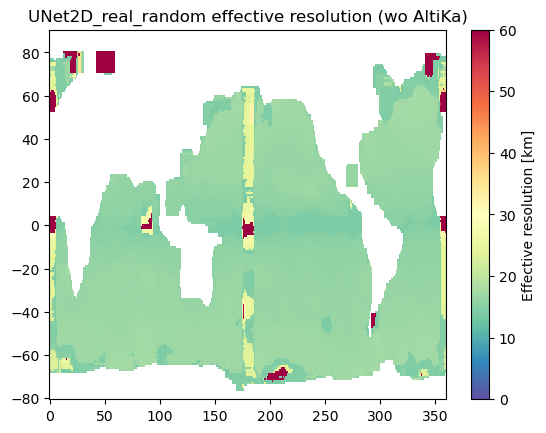

In [4]:
# 3) OSSE reconstruction (2024) -> msla_interpolated
recon = xr.open_dataset('/Odyssey/private/n23nguye/4dvarnet-global-mapping-Daniel-version/inference/outputs/'
                        'Train_real_random_7nadirNSwot_train20232025withoutAlg_UNet2D_OSSEInference-n10-std0.2.nc')['sla']
if 'lat' in recon.dims or 'lat' in recon.coords: recon = recon.rename({'lat':'latitude','lon':'longitude'})
msla_interpolated = sample_grid_on_track(recon, t, lat, lon, year_shift=0)

# 4) assemble the 1-D ds_interp the challenge expects (exact names!)
ds_interp = xr.Dataset(
    dict(sla_unfiltered=('time', sla_unfiltered.astype('float64')),
         msla_interpolated=('time', msla_interpolated.astype('float64'))),
    coords=dict(time=('time', t), latitude=('time', lat.astype('float64')), longitude=('time', lon.astype('float64'))),
).sortby('time').dropna('time')
print('points feeding spectral analysis:', ds_interp.time.size)

# 5) effective resolution via the data-challenge routine
import os; os.makedirs('./results', exist_ok=True)
psd_out = './results/psd_Train_real_random_7nadirNSwot_train20232025withoutAlg_UNet2D_OSSEInference_wo_altika.nc'
compute_psd_scores_v2(ds_interp, psd_out, method_name='Train_real_random_7nadirNSwot_train20232025withoutAlg_UNet2D_OSSEInference-wo-altika')

# 6) global number + safe map (avoids the cartopy colorbar bug you hit before)
import matplotlib.pyplot as plt
psd = xr.open_dataset(psd_out)
print(f"Averaged effective resolution: {float(np.nanmean(psd.effective_resolution)):.4f} km")
m = plt.pcolormesh(psd.lon, psd.lat, psd.effective_resolution, vmin=0, vmax=60, cmap='Spectral_r', shading='auto')
plt.colorbar(m, label='Effective resolution [km]'); plt.title('UNet2D_real_random effective resolution (wo AltiKa)'); plt.show()

points feeding spectral analysis: 14644826
Averaged effective resolution: 17.3304 km


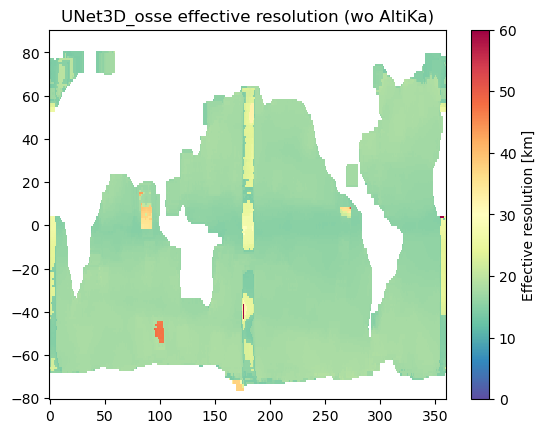

In [5]:
# 3) OSSE reconstruction (2024) -> msla_interpolated
recon = xr.open_dataset('/Odyssey/private/n23nguye/4dvarnet-global-mapping-Daniel-version/inference/outputs/'
                        'UNet3DTransformer_bs8_7nadirNSwot_osse_random_pretrain_GAPFREEtarget_OSSEinference-n10-std0.2.nc')['sla']
if 'lat' in recon.dims or 'lat' in recon.coords: recon = recon.rename({'lat':'latitude','lon':'longitude'})
msla_interpolated = sample_grid_on_track(recon, t, lat, lon, year_shift=0)

# 4) assemble the 1-D ds_interp the challenge expects (exact names!)
ds_interp = xr.Dataset(
    dict(sla_unfiltered=('time', sla_unfiltered.astype('float64')),
         msla_interpolated=('time', msla_interpolated.astype('float64'))),
    coords=dict(time=('time', t), latitude=('time', lat.astype('float64')), longitude=('time', lon.astype('float64'))),
).sortby('time').dropna('time')
print('points feeding spectral analysis:', ds_interp.time.size)

# 5) effective resolution via the data-challenge routine
import os; os.makedirs('./results', exist_ok=True)
psd_out = './results/psd_UNet3DTransformer_bs8_7nadirNSwot_osse_random_pretrain_GAPFREEtarget_OSSEinference_wo_altika.nc'
compute_psd_scores_v2(ds_interp, psd_out, method_name='UNet3DTransformer_bs8_7nadirNSwot_osse_random_pretrain_GAPFREEtarget_OSSEinference-wo-altika')

# 6) global number + safe map (avoids the cartopy colorbar bug you hit before)
import matplotlib.pyplot as plt
psd = xr.open_dataset(psd_out)
print(f"Averaged effective resolution: {float(np.nanmean(psd.effective_resolution)):.4f} km")
m = plt.pcolormesh(psd.lon, psd.lat, psd.effective_resolution, vmin=0, vmax=60, cmap='Spectral_r', shading='auto')
plt.colorbar(m, label='Effective resolution [km]'); plt.title('UNet3D_osse effective resolution (wo AltiKa)'); plt.show()

points feeding spectral analysis: 14644826
Averaged effective resolution: 24.1883 km


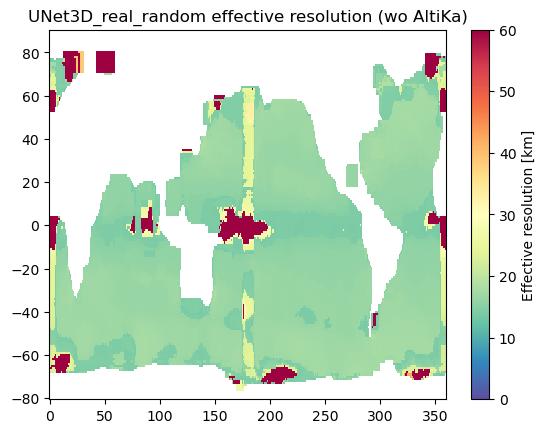

In [6]:
# 3) OSSE reconstruction (2024) -> msla_interpolated
recon = xr.open_dataset('/Odyssey/private/n23nguye/4dvarnet-global-mapping-Daniel-version/inference/outputs/'
                        'UNet3DTransformer_bs8_real_random_7nadirNSwot_train20232025withoutAlg_OSSEinference-n10-std0.2.nc')['sla']
if 'lat' in recon.dims or 'lat' in recon.coords: recon = recon.rename({'lat':'latitude','lon':'longitude'})
msla_interpolated = sample_grid_on_track(recon, t, lat, lon, year_shift=0)

# 4) assemble the 1-D ds_interp the challenge expects (exact names!)
ds_interp = xr.Dataset(
    dict(sla_unfiltered=('time', sla_unfiltered.astype('float64')),
         msla_interpolated=('time', msla_interpolated.astype('float64'))),
    coords=dict(time=('time', t), latitude=('time', lat.astype('float64')), longitude=('time', lon.astype('float64'))),
).sortby('time').dropna('time')
print('points feeding spectral analysis:', ds_interp.time.size)

# 5) effective resolution via the data-challenge routine
import os; os.makedirs('./results', exist_ok=True)
psd_out = './results/psd_UNet3DTransformer_bs8_real_random_7nadirNSwot_train20232025withoutAlg_OSSEinference_wo_altika.nc'
compute_psd_scores_v2(ds_interp, psd_out, method_name='UNet3DTransformer_bs8_real_random_7nadirNSwot_train20232025withoutAlg_OSSEinference-wo-altika')

# 6) global number + safe map (avoids the cartopy colorbar bug you hit before)
import matplotlib.pyplot as plt
psd = xr.open_dataset(psd_out)
print(f"Averaged effective resolution: {float(np.nanmean(psd.effective_resolution)):.4f} km")
m = plt.pcolormesh(psd.lon, psd.lat, psd.effective_resolution, vmin=0, vmax=60, cmap='Spectral_r', shading='auto')
plt.colorbar(m, label='Effective resolution [km]'); plt.title('UNet3D_real_random effective resolution (wo AltiKa)'); plt.show()

points feeding spectral analysis: 14644826
Averaged effective resolution: 17.3403 km


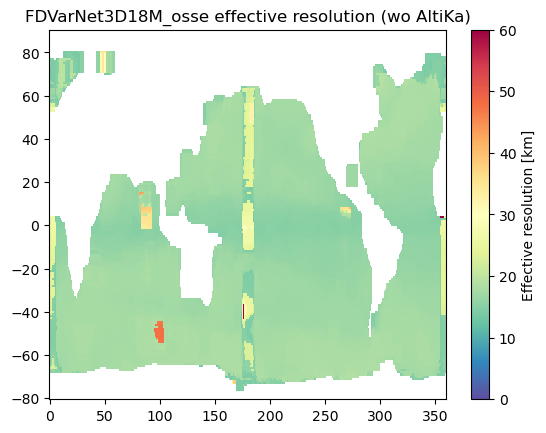

In [7]:
# 3) OSSE reconstruction (2024) -> msla_interpolated
recon = xr.open_dataset('/Odyssey/private/n23nguye/4dvarnet-global-mapping-Daniel-version/inference/outputs/'
                        'FDVarNet3D18M_bs2_7nadirNSwot_osse_random_pretrain_GAPFREEtarget_OSSEinference-n10-std0.2.nc')['sla']
if 'lat' in recon.dims or 'lat' in recon.coords: recon = recon.rename({'lat':'latitude','lon':'longitude'})
msla_interpolated = sample_grid_on_track(recon, t, lat, lon, year_shift=0)

# 4) assemble the 1-D ds_interp the challenge expects (exact names!)
ds_interp = xr.Dataset(
    dict(sla_unfiltered=('time', sla_unfiltered.astype('float64')),
         msla_interpolated=('time', msla_interpolated.astype('float64'))),
    coords=dict(time=('time', t), latitude=('time', lat.astype('float64')), longitude=('time', lon.astype('float64'))),
).sortby('time').dropna('time')
print('points feeding spectral analysis:', ds_interp.time.size)

# 5) effective resolution via the data-challenge routine
import os; os.makedirs('./results', exist_ok=True)
psd_out = './results/psd_FDVarNet3D18M_bs2_7nadirNSwot_osse_random_pretrain_GAPFREEtarget_OSSEinference_wo_altika.nc'
compute_psd_scores_v2(ds_interp, psd_out, method_name='FDVarNet3D18M_bs2_7nadirNSwot_osse_random_pretrain_GAPFREEtarget_OSSEinference-wo-altika')

# 6) global number + safe map (avoids the cartopy colorbar bug you hit before)
import matplotlib.pyplot as plt
psd = xr.open_dataset(psd_out)
print(f"Averaged effective resolution: {float(np.nanmean(psd.effective_resolution)):.4f} km")
m = plt.pcolormesh(psd.lon, psd.lat, psd.effective_resolution, vmin=0, vmax=60, cmap='Spectral_r', shading='auto')
plt.colorbar(m, label='Effective resolution [km]'); plt.title('FDVarNet3D18M_osse effective resolution (wo AltiKa)'); plt.show()

points feeding spectral analysis: 14644826
Averaged effective resolution: 17.1652 km


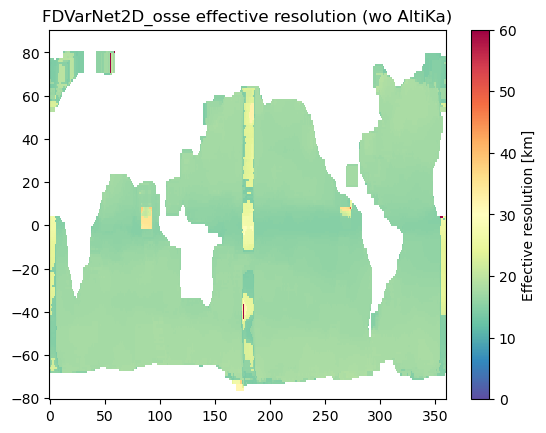

In [8]:
# 3) OSSE reconstruction (2024) -> msla_interpolated
recon = xr.open_dataset('/Odyssey/private/n23nguye/4dvarnet-global-mapping-Daniel-version/inference/outputs/'
                        'FDVarNet_bs2_7nadirNSwot_osse_random_pretrain_GAPFREEtarget_OSSEinference-n10-std0.2.nc')['sla']
if 'lat' in recon.dims or 'lat' in recon.coords: recon = recon.rename({'lat':'latitude','lon':'longitude'})
msla_interpolated = sample_grid_on_track(recon, t, lat, lon, year_shift=0)

# 4) assemble the 1-D ds_interp the challenge expects (exact names!)
ds_interp = xr.Dataset(
    dict(sla_unfiltered=('time', sla_unfiltered.astype('float64')),
         msla_interpolated=('time', msla_interpolated.astype('float64'))),
    coords=dict(time=('time', t), latitude=('time', lat.astype('float64')), longitude=('time', lon.astype('float64'))),
).sortby('time').dropna('time')
print('points feeding spectral analysis:', ds_interp.time.size)

# 5) effective resolution via the data-challenge routine
import os; os.makedirs('./results', exist_ok=True)
psd_out = './results/psd_FDVarNet_bs2_7nadirNSwot_osse_random_pretrain_GAPFREEtarget_OSSEinference_wo_altika.nc'
compute_psd_scores_v2(ds_interp, psd_out, method_name='FDVarNet_bs2_7nadirNSwot_osse_random_pretrain_GAPFREEtarget_OSSEinference-wo-altika')

# 6) global number + safe map (avoids the cartopy colorbar bug you hit before)
import matplotlib.pyplot as plt
psd = xr.open_dataset(psd_out)
print(f"Averaged effective resolution: {float(np.nanmean(psd.effective_resolution)):.4f} km")
m = plt.pcolormesh(psd.lon, psd.lat, psd.effective_resolution, vmin=0, vmax=60, cmap='Spectral_r', shading='auto')
plt.colorbar(m, label='Effective resolution [km]'); plt.title('FDVarNet2D_osse effective resolution (wo AltiKa)'); plt.show()

points feeding spectral analysis: 14644826
Averaged effective resolution: 19.9376 km


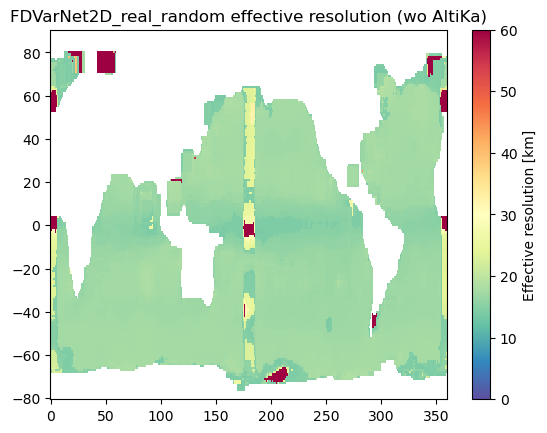

In [9]:
# 3) OSSE reconstruction (2024) -> msla_interpolated
recon = xr.open_dataset('/Odyssey/private/n23nguye/4dvarnet-global-mapping-Daniel-version/inference/outputs/'
                        'FDVarNet_bs2_real_random_7nadirNSwot_train20232025withoutAlg_OSSEinference-n10-std0.2.nc')['sla']
if 'lat' in recon.dims or 'lat' in recon.coords: recon = recon.rename({'lat':'latitude','lon':'longitude'})
msla_interpolated = sample_grid_on_track(recon, t, lat, lon, year_shift=0)

# 4) assemble the 1-D ds_interp the challenge expects (exact names!)
ds_interp = xr.Dataset(
    dict(sla_unfiltered=('time', sla_unfiltered.astype('float64')),
         msla_interpolated=('time', msla_interpolated.astype('float64'))),
    coords=dict(time=('time', t), latitude=('time', lat.astype('float64')), longitude=('time', lon.astype('float64'))),
).sortby('time').dropna('time')
print('points feeding spectral analysis:', ds_interp.time.size)

# 5) effective resolution via the data-challenge routine
import os; os.makedirs('./results', exist_ok=True)
psd_out = './results/psd_FDVarNet_bs2_real_random_7nadirNSwot_train20232025withoutAlg_OSSEinference_wo_altika.nc'
compute_psd_scores_v2(ds_interp, psd_out, method_name='FDVarNet_bs2_real_random_7nadirNSwot_train20232025withoutAlg_OSSEinference-wo-altika')

# 6) global number + safe map (avoids the cartopy colorbar bug you hit before)
import matplotlib.pyplot as plt
psd = xr.open_dataset(psd_out)
print(f"Averaged effective resolution: {float(np.nanmean(psd.effective_resolution)):.4f} km")
m = plt.pcolormesh(psd.lon, psd.lat, psd.effective_resolution, vmin=0, vmax=60, cmap='Spectral_r', shading='auto')
plt.colorbar(m, label='Effective resolution [km]'); plt.title('FDVarNet2D_real_random effective resolution (wo AltiKa)'); plt.show()

points feeding spectral analysis: 14644826
Averaged effective resolution: 18.1839 km


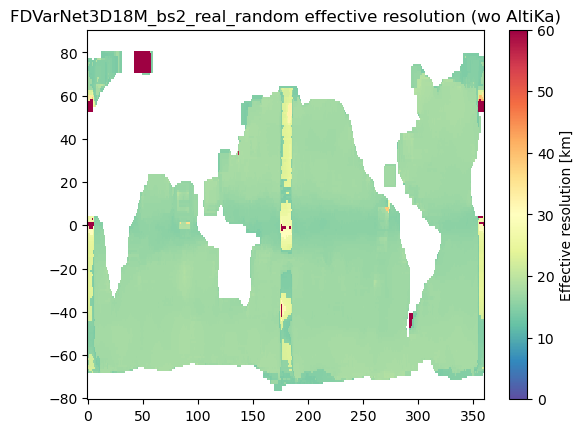

In [10]:
# 3) OSSE reconstruction (2024) -> msla_interpolated
recon = xr.open_dataset('/Odyssey/private/n23nguye/4dvarnet-global-mapping-Daniel-version/inference/outputs/'
                        'FDVarNet3D18M_bs2_real_random_7nadirNSwot_train20232025withoutAlg_OSSEinference-n10-std0.2.nc')['sla']
if 'lat' in recon.dims or 'lat' in recon.coords: recon = recon.rename({'lat':'latitude','lon':'longitude'})
msla_interpolated = sample_grid_on_track(recon, t, lat, lon, year_shift=0)

# 4) assemble the 1-D ds_interp the challenge expects (exact names!)
ds_interp = xr.Dataset(
    dict(sla_unfiltered=('time', sla_unfiltered.astype('float64')),
         msla_interpolated=('time', msla_interpolated.astype('float64'))),
    coords=dict(time=('time', t), latitude=('time', lat.astype('float64')), longitude=('time', lon.astype('float64'))),
).sortby('time').dropna('time')
print('points feeding spectral analysis:', ds_interp.time.size)

# 5) effective resolution via the data-challenge routine
import os; os.makedirs('./results', exist_ok=True)
psd_out = './results/psd_FDVarNet3D18M_bs2_real_random_7nadirNSwot_train20232025withoutAlg_OSSEinference_wo_altika.nc'
compute_psd_scores_v2(ds_interp, psd_out, method_name='FDVarNet3D18M_bs2_real_random_7nadirNSwot_train20232025withoutAlg_OSSEinference-wo-altika')

# 6) global number + safe map (avoids the cartopy colorbar bug you hit before)
import matplotlib.pyplot as plt
psd = xr.open_dataset(psd_out)
print(f"Averaged effective resolution: {float(np.nanmean(psd.effective_resolution)):.4f} km")
m = plt.pcolormesh(psd.lon, psd.lat, psd.effective_resolution, vmin=0, vmax=60, cmap='Spectral_r', shading='auto')
plt.colorbar(m, label='Effective resolution [km]'); plt.title('FDVarNet3D18M_bs2_real_random effective resolution (wo AltiKa)'); plt.show()